# Question 1: Data Cleaning and Feature Exploration

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('automobileEDA.csv')

df.head()

,symboling,normalized-losses,make,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,length,...,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price,city-L/100km,horsepower-binned,diesel,gas
0,3,122,alfa-romero,std,two,convertible,rwd,front,88.6,0.811148,...,9.0,111.0,5000.0,21,27,13495,11.190476,Medium,0,1
1,3,122,alfa-romero,std,two,convertible,rwd,front,88.6,0.811148,...,9.0,111.0,5000.0,21,27,16500,11.190476,Medium,0,1
2,1,122,alfa-romero,std,two,hatchback,rwd,front,94.5,0.822681,...,9.0,154.0,5000.0,19,26,16500,12.368421,Medium,0,1
3,2,164,audi,std,four,sedan,fwd,front,99.8,0.848630,...,10.0,102.0,5500.0,24,30,13950,9.791667,Medium,0,1
4,2,164,audi,std,four,sedan,4wd,front,99.4,0.848630,...,8.0,115.0,5500.0,18,22,17450,13.055556,Medium,0,1


In [6]:
# Data shape, rows and columns
df.shape

(201, 29)

In [7]:
# view dataset information 
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 201 entries, 0 to 200
Data columns (total 29 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   symboling          201 non-null    int64  
 1   normalized-losses  201 non-null    int64  
 2   make               201 non-null    str    
 3   aspiration         201 non-null    str    
 4   num-of-doors       201 non-null    str    
 5   body-style         201 non-null    str    
 6   drive-wheels       201 non-null    str    
 7   engine-location    201 non-null    str    
 8   wheel-base         201 non-null    float64
 9   length             201 non-null    float64
 10  width              201 non-null    float64
 11  height             201 non-null    float64
 12  curb-weight        201 non-null    int64  
 13  engine-type        201 non-null    str    
 14  num-of-cylinders   201 non-null    str    
 15  engine-size        201 non-null    int64  
 16  fuel-system        201 non-null    st

In [8]:
# Check missing values
df.isnull().sum()

symboling            0
normalized-losses    0
make                 0
aspiration           0
num-of-doors         0
body-style           0
drive-wheels         0
engine-location      0
wheel-base           0
length               0
width                0
height               0
curb-weight          0
engine-type          0
num-of-cylinders     0
engine-size          0
fuel-system          0
bore                 0
stroke               4
compression-ratio    0
horsepower           0
peak-rpm             0
city-mpg             0
highway-mpg          0
price                0
city-L/100km         0
horsepower-binned    1
diesel               0
gas                  0
dtype: int64

In [9]:
missing = df.isnull().sum()

missing[missing > 0]

stroke               4
horsepower-binned    1
dtype: int64

In [10]:
# Calculate missing percentages

missing_percent = (df.isnull().sum()/len(df))*100

missing_percent[missing_percent>0]


stroke               1.990050
horsepower-binned    0.497512
dtype: float64

In [11]:
# Handle missing values (Numerical columns)
num_cols = df.select_dtypes(include=np.number).columns

for col in num_cols:
    df[col] = df[col].fillna(df[col].mean())

In [12]:
# Handle missing values (Categorical columns)
cat_cols = df.select_dtypes(exclude=np.number).columns

for col in cat_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

In [13]:
df.isnull().sum().sum()

np.int64(0)

In [14]:
# check duplicate records
df.duplicated().sum()

np.int64(0)

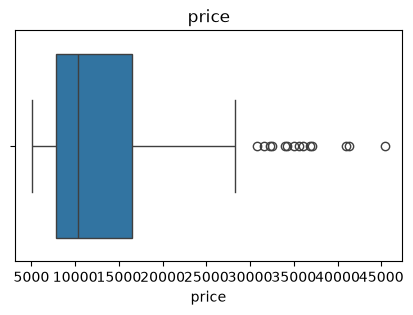

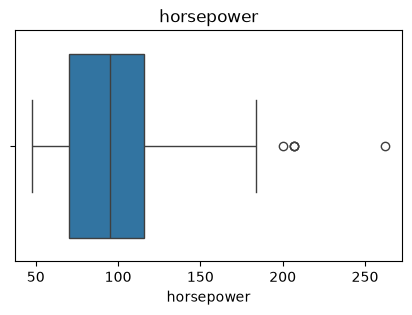

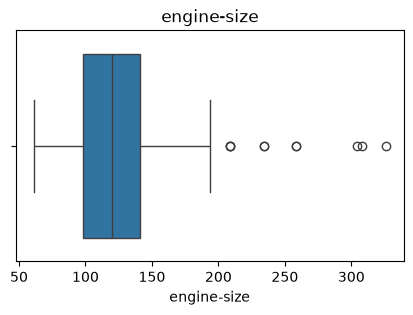

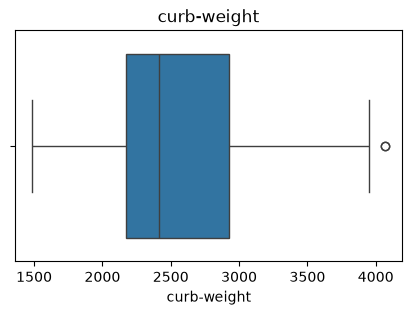

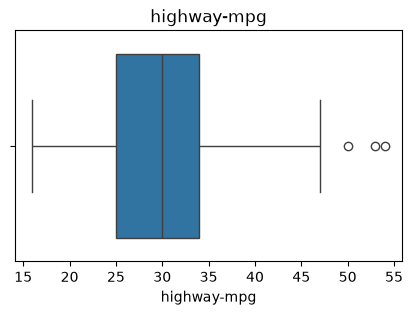

In [15]:
# Detect outliers 
cols = ['price',
        'horsepower',
        'engine-size',
        'curb-weight',
        'highway-mpg']

for col in cols:
    plt.figure(figsize=(5,3))
    sns.boxplot(x=df[col])
    plt.title(col)
    plt.show()

In [16]:
# Handle outliers using IQR

def cap_outliers(column):

    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5*IQR
    upper = Q3 + 1.5*IQR

    df[column] = np.where(df[column] < lower,
                          lower,
                          np.where(df[column] > upper,
                                   upper,
                                   df[column]))

In [17]:
numeric_columns = df.select_dtypes(include=np.number).columns

for col in numeric_columns:
    cap_outliers(col)

In [18]:
#Save the cleaned dataset
df.to_csv('cleaned_automobileEDA.csv', index=False)

print("Dataset saved successfully.")

Dataset saved successfully.


#### The automobile dataset contained 201 observations and 29 variables. The target variable was price, while the remaining variables were considered potential predictors of automobile price. Data quality assessment was conducted by checking missing values, duplicate records, and outliers. Missing values were replaced using mean imputation for numerical variables and mode imputation for categorical variables. Duplicate records were removed where present. Outliers were detected using boxplots and treated using the Interquartile Range (IQR) method. The cleaned dataset was saved as cleaned_automobileEDA.csv for further analysis.

# Question 2:
#### Analyse patterns and run descriptive statistics for the dataset. Give summary statistics for the continuous variables and frequency counts for the categorical variables. Use graphs to show how price and the other variables are distributed, and summarize the findings and patterns observed.

In [19]:
# Generate summary statistics for continuous variables

df.describe()

,symboling,normalized-losses,wheel-base,length,width,height,curb-weight,engine-size,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price,city-L/100km,diesel,gas
count,201.000000,201.000000,201.000000,201.000000,201.000000,201.000000,201.000000,201.000000,201.000000,201.000000,201.000000,201.000000,201.000000,201.000000,201.000000,201.000000,201.000000,201.0,201.0
mean,0.840796,121.378109,98.750498,0.837118,0.914452,53.766667,2555.621891,124.417910,3.330692,3.263421,9.036915,102.619464,5117.167855,25.164179,30.614428,12762.781095,9.944145,0.0,1.0
std,1.254802,30.125343,5.925743,0.059171,0.027479,2.447822,517.165519,33.498537,0.268072,0.278814,0.787910,35.051751,476.587061,6.370668,6.603737,6660.129987,2.534599,0.0,0.0
min,-2.000000,65.000000,86.600000,0.681163,0.838194,47.800000,1488.000000,61.000000,2.540000,2.660000,7.400000,48.000000,4150.000000,13.000000,16.000000,5118.000000,4.795918,0.0,1.0
25%,0.000000,101.000000,94.500000,0.801538,0.890278,52.000000,2169.000000,98.000000,3.150000,3.110000,8.600000,70.000000,4800.000000,19.000000,25.000000,7775.000000,7.833333,0.0,1.0
50%,1.000000,122.000000,97.000000,0.832292,0.909722,54.100000,2414.000000,120.000000,3.310000,3.290000,9.000000,95.000000,5125.369458,24.000000,30.000000,10295.000000,9.791667,0.0,1.0
75%,2.000000,137.000000,102.400000,0.881788,0.925000,55.500000,2926.000000,141.000000,3.580000,3.410000,9.400000,116.000000,5500.000000,30.000000,34.000000,16500.000000,12.368421,0.0,1.0
max,3.000000,191.000000,114.250000,1.000000,0.977083,59.800000,4061.500000,205.500000,3.940000,3.860000,10.600000,185.000000,6550.000000,46.500000,47.500000,29587.500000,18.076923,0.0,1.0


In [20]:
df.describe().round(2)

,symboling,normalized-losses,wheel-base,length,width,height,curb-weight,engine-size,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price,city-L/100km,diesel,gas
count,201.00,201.00,201.00,201.00,201.00,201.00,201.00,201.00,201.00,201.00,201.00,201.00,201.00,201.00,201.00,201.00,201.00,201.0,201.0
mean,0.84,121.38,98.75,0.84,0.91,53.77,2555.62,124.42,3.33,3.26,9.04,102.62,5117.17,25.16,30.61,12762.78,9.94,0.0,1.0
std,1.25,30.13,5.93,0.06,0.03,2.45,517.17,33.50,0.27,0.28,0.79,35.05,476.59,6.37,6.60,6660.13,2.53,0.0,0.0
min,-2.00,65.00,86.60,0.68,0.84,47.80,1488.00,61.00,2.54,2.66,7.40,48.00,4150.00,13.00,16.00,5118.00,4.80,0.0,1.0
25%,0.00,101.00,94.50,0.80,0.89,52.00,2169.00,98.00,3.15,3.11,8.60,70.00,4800.00,19.00,25.00,7775.00,7.83,0.0,1.0
50%,1.00,122.00,97.00,0.83,0.91,54.10,2414.00,120.00,3.31,3.29,9.00,95.00,5125.37,24.00,30.00,10295.00,9.79,0.0,1.0
75%,2.00,137.00,102.40,0.88,0.92,55.50,2926.00,141.00,3.58,3.41,9.40,116.00,5500.00,30.00,34.00,16500.00,12.37,0.0,1.0
max,3.00,191.00,114.25,1.00,0.98,59.80,4061.50,205.50,3.94,3.86,10.60,185.00,6550.00,46.50,47.50,29587.50,18.08,0.0,1.0


### The average automobile price was approximately 12,763, with prices ranging between 5,118 and 29,587. 
### Variables such as engine-size, horsepower and curb-weight showed considerable variability,indicating differences in vehicle performance and design

In [21]:
# Frequency counts for categorical variables
cat_cols = df.select_dtypes(exclude=np.number).columns

print(cat_cols)

Index(['make', 'aspiration', 'num-of-doors', 'body-style', 'drive-wheels',
       'engine-location', 'engine-type', 'num-of-cylinders', 'fuel-system',
       'horsepower-binned'],
      dtype='str')


In [22]:
for col in cat_cols:
    print("\n", col)
    print(df[col].value_counts())


 make
make
toyota           32
nissan           18
mazda            17
honda            13
mitsubishi       13
subaru           12
volkswagen       12
peugot           11
volvo            11
dodge             9
bmw               8
mercedes-benz     8
plymouth          7
audi              6
saab              6
porsche           4
alfa-romero       3
chevrolet         3
jaguar            3
isuzu             2
renault           2
mercury           1
Name: count, dtype: int64

 aspiration
aspiration
std      165
turbo     36
Name: count, dtype: int64

 num-of-doors
num-of-doors
four    115
two      86
Name: count, dtype: int64

 body-style
body-style
sedan          94
hatchback      68
wagon          25
hardtop         8
convertible     6
Name: count, dtype: int64

 drive-wheels
drive-wheels
fwd    118
rwd     75
4wd      8
Name: count, dtype: int64

 engine-location
engine-location
front    198
rear       3
Name: count, dtype: int64

 engine-type
engine-type
ohc      145
ohcf      15
ohc

### Important variables to summarise

In [23]:
df['make'].value_counts()

make
toyota           32
nissan           18
mazda            17
honda            13
mitsubishi       13
subaru           12
volkswagen       12
peugot           11
volvo            11
dodge             9
bmw               8
mercedes-benz     8
plymouth          7
audi              6
saab              6
porsche           4
alfa-romero       3
chevrolet         3
jaguar            3
isuzu             2
renault           2
mercury           1
Name: count, dtype: int64

In [24]:
df['body-style'].value_counts()

body-style
sedan          94
hatchback      68
wagon          25
hardtop         8
convertible     6
Name: count, dtype: int64

In [25]:
df['drive-wheels'].value_counts()

drive-wheels
fwd    118
rwd     75
4wd      8
Name: count, dtype: int64

In [26]:
df['aspiration'].value_counts()

aspiration
std      165
turbo     36
Name: count, dtype: int64

In [27]:
df['num-of-cylinders'].value_counts()

num-of-cylinders
four      157
six        24
five       10
two         4
eight       4
three       1
twelve      1
Name: count, dtype: int64

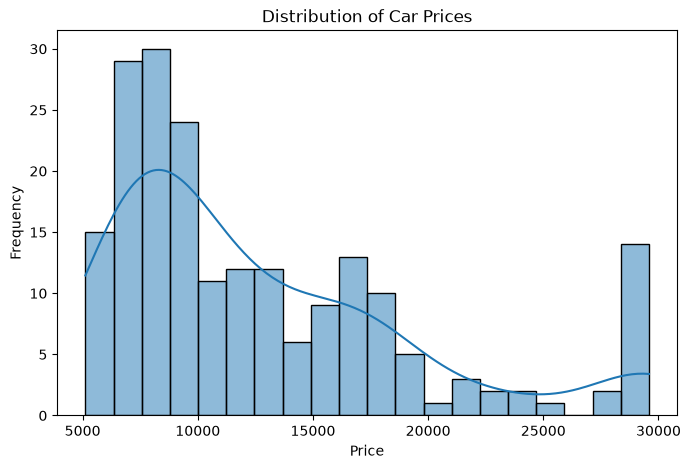

In [28]:
plt.figure(figsize=(8,5))

sns.histplot(df['price'],
             bins=20,
             kde=True)

plt.title("Distribution of Car Prices")
plt.xlabel("Price")
plt.ylabel("Frequency")

plt.show()

#### Most vehicles are concentrated in the lower and middle price ranges, while a smaller number of luxury vehicles appear at higher prices, creating a right-skewed distribution.

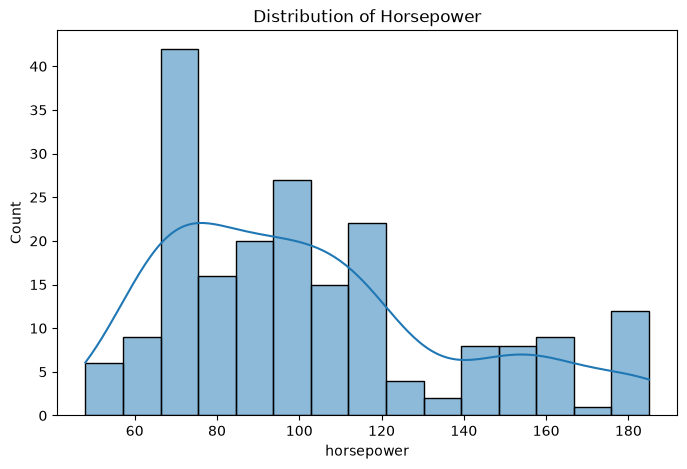

In [29]:
plt.figure(figsize=(8,5))

sns.histplot(df['horsepower'],
             bins=15,
             kde=True)

plt.title("Distribution of Horsepower")

plt.show()

#### Most automobiles have moderate horsepower values, while high-performance vehicles occur less frequently.

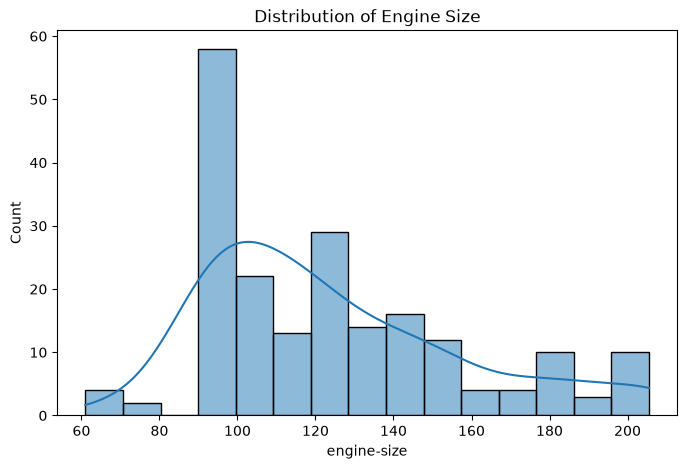

In [30]:
plt.figure(figsize=(8,5))

sns.histplot(df['engine-size'],
             bins=15,
             kde=True)

plt.title("Distribution of Engine Size")

plt.show()

#### Engine sizes are mainly concentrated in the low to medium range, with a few vehicles having significantly larger engines.

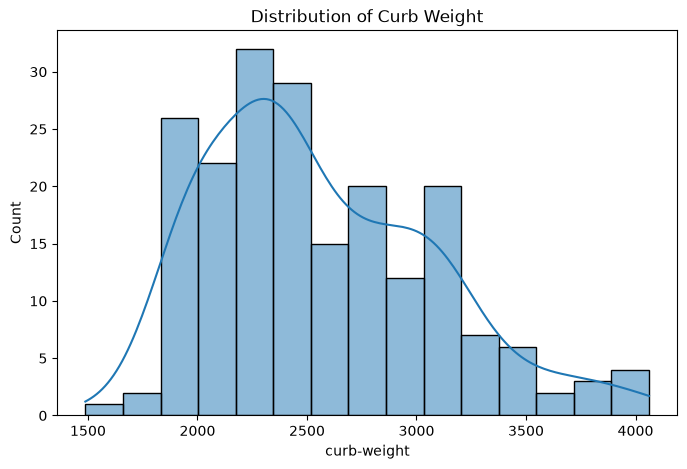

In [31]:
plt.figure(figsize=(8,5))

sns.histplot(df['curb-weight'],
             bins=15,
             kde=True)

plt.title("Distribution of Curb Weight")

plt.show()

#### Most vehicles fall within the medium-weight category, with relatively few extremely heavy vehicles

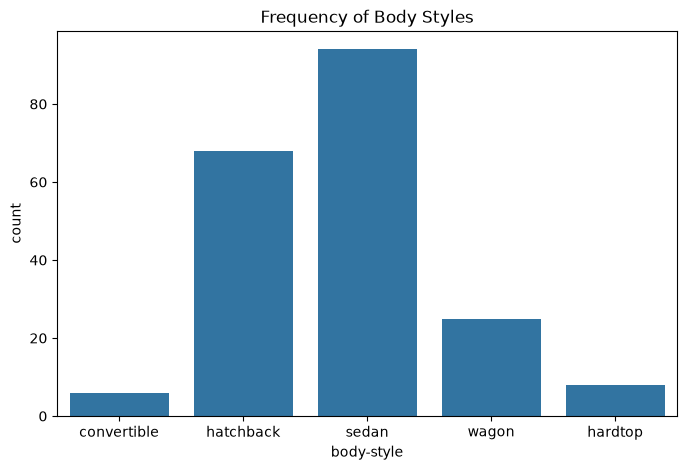

In [32]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x='body-style'
)

plt.title("Frequency of Body Styles")

plt.show()

#### Sedans and hatchbacks dominate the dataset, while convertibles and hardtops appear less frequently.

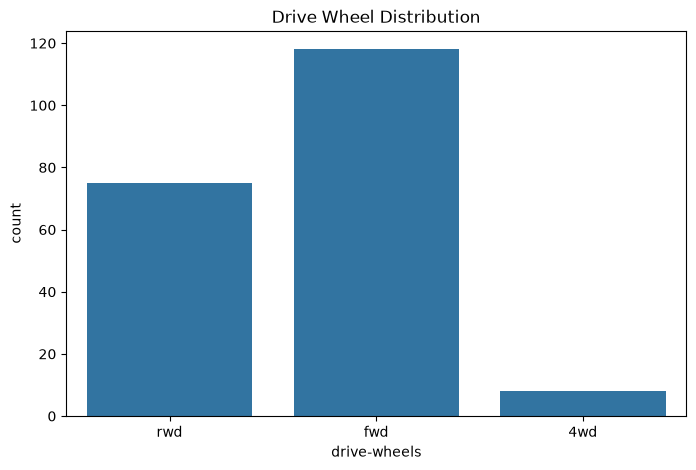

In [33]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x='drive-wheels'
)

plt.title("Drive Wheel Distribution")

plt.show()


#### Front-wheel drive vehicles appear most frequently, followed by rear-wheel drive vehicles. Four-wheel drive vehicles are less common

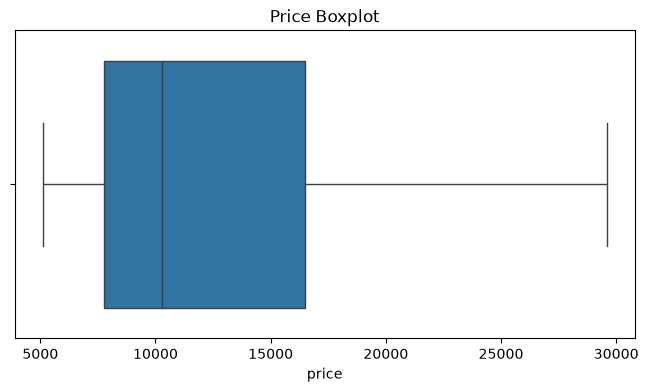

In [34]:
plt.figure(figsize=(8,4))

sns.boxplot(x=df['price'])

plt.title("Price Boxplot")

plt.show()

#### The boxplot indicates substantial variability in automobile prices with several high-value vehicles appearing as outliers

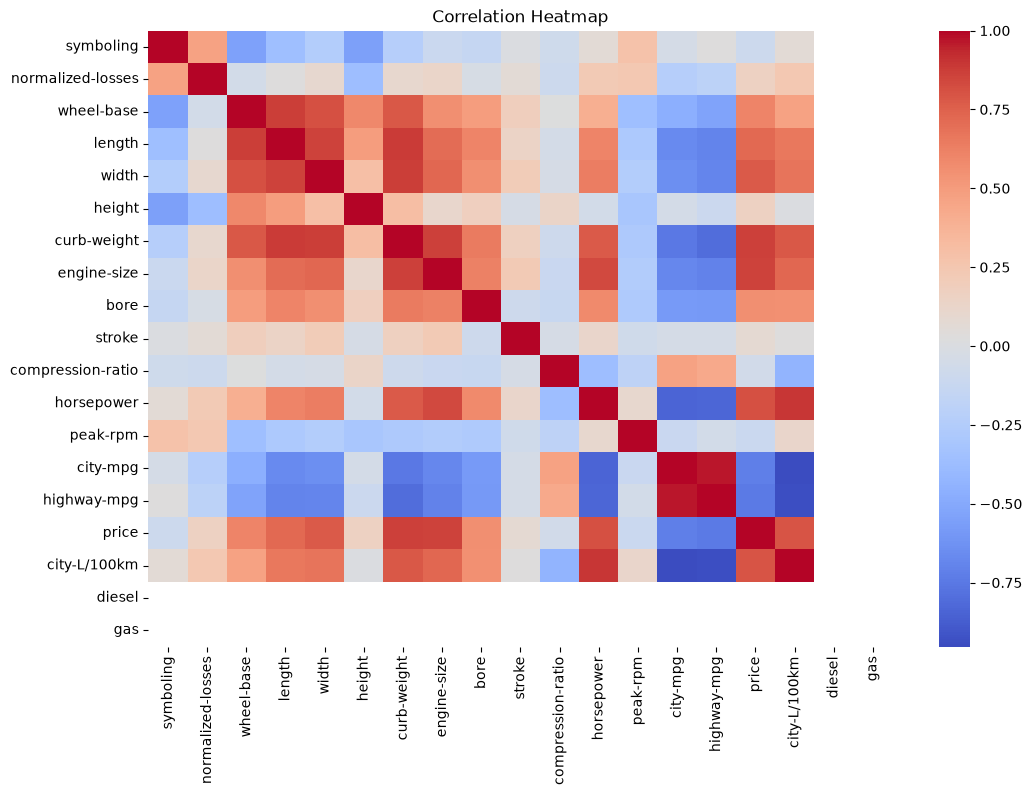

In [35]:
plt.figure(figsize=(12,8))

sns.heatmap(
    df.corr(numeric_only=True),
    cmap='coolwarm'
)

plt.title("Correlation Heatmap")

plt.show()

#### After running the heatmap, you'll probably find:Strong Positive Correlations with Price..Engine Size, Horsepower, Curb Weight, Width
#### Strong Negative Correlations with Price, City MPG, Highway MPG
#### Meaning:
#### Vehicles with larger engines, higher horsepower and greater weight tend to be more expensive, whereas fuel-efficient vehicles generally tend to be less expensive.

Descriptive Statistics. Descriptive statistics were generated for all numerical variables using the describe() function. The statistics showed the distribution, central tendency and variability of each continuous variable. Automobile prices displayed substantial variation across different vehicle models.

Frequency Analysis. Frequency counts were produced for categorical variables including make, body-style, drive-wheels and aspiration. Sedans and hatchbacks were the most common body styles, while front-wheel-drive vehicles dominated the dataset.

Distribution Analysis. Histograms showed that price, horsepower and engine-size were positively skewed, with a small number of high-value vehicles contributing to extreme values. Boxplots confirmed the presence of premium-priced vehicle outliers.

Pattern Analysis. Correlation analysis indicated that engine-size, horsepower and curb-weight exhibited strong positive relationships with price. Fuel economy variables such as city-mpg and highway-mpg showed negative relationships with price, suggesting that larger and more powerful vehicles are generally more expensive.

# Question 3:
#### Group the data by identified parameters, such as drive-wheels and body-style. Find the average price for each group and present the results using visuals and statistics. Find which groups have the highest and lowest prices.

In [36]:
drive_wheels_group = df.groupby('drive-wheels')['price'].mean()

drive_wheels_group

drive-wheels
4wd    10241.000000
fwd     9244.779661
rwd    18566.760000
Name: price, dtype: float64

In [37]:
drive_wheels_group = df.groupby('drive-wheels')['price'].mean().round(2)

print(drive_wheels_group)

drive-wheels
4wd    10241.00
fwd     9244.78
rwd    18566.76
Name: price, dtype: float64


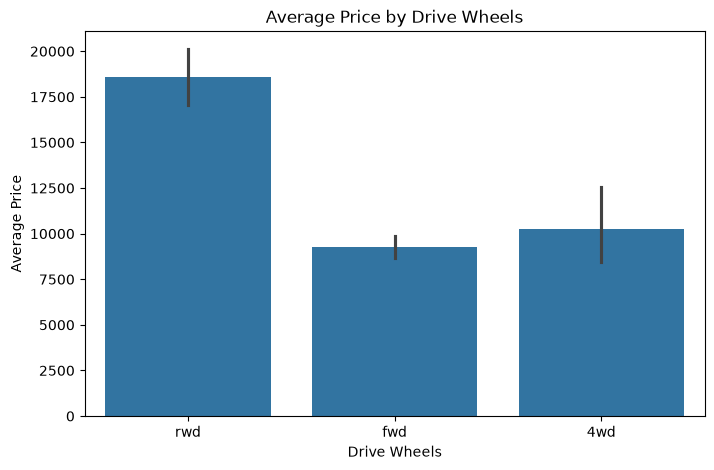

In [38]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=df,
    x='drive-wheels',
    y='price',
    estimator=np.mean
)

plt.title('Average Price by Drive Wheels')
plt.xlabel('Drive Wheels')
plt.ylabel('Average Price')

plt.show()

#Average Price by drivewheels

In [39]:
drive_wheels_group = df.groupby('drive-wheels')['price'].mean()

print("Highest:")
print(drive_wheels_group.idxmax(),
      drive_wheels_group.max())

print("Lowest:")
print(drive_wheels_group.idxmin(),
      drive_wheels_group.min())

Highest:
rwd 18566.76
Lowest:
fwd 9244.77966101695


#Rear-wheel-drive vehicles recorded the highest average price, while front-wheel-drive vehicles recorded the lowest average price. 
This suggests that drive-wheel configuration influences vehicle pricing

In [40]:
#Average Price by body style
body_style_group = df.groupby('body-style')['price'].mean().round(2)

body_style_group

body-style
convertible    19739.00
hardtop        19309.31
hatchback       9957.44
sedan          13893.68
wagon          12371.96
Name: price, dtype: float64

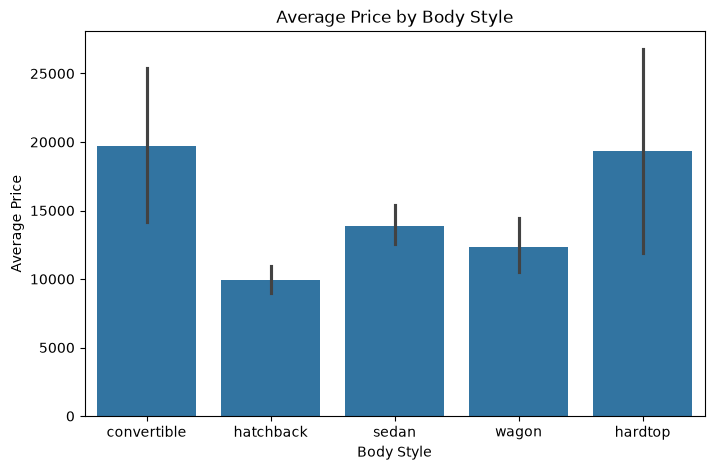

In [41]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=df,
    x='body-style',
    y='price',
    estimator=np.mean
)

plt.title('Average Price by Body Style')
plt.xlabel('Body Style')
plt.ylabel('Average Price')

plt.show()

In [42]:
body_style_group = df.groupby('body-style')['price'].mean()

print("Highest:")
print(body_style_group.idxmax(),
      body_style_group.max())

print("Lowest:")
print(body_style_group.idxmin(),
      body_style_group.min())

Highest:
convertible 19739.0
Lowest:
hatchback 9957.441176470587


In [43]:
#Create a pivot table
pivot_table = df.pivot_table(
    values='price',
    index='drive-wheels',
    columns='body-style',
    aggfunc='mean'
)

pivot_table.round(2)

body-style,convertible,hardtop,hatchback,sedan,wagon
drive-wheels,,,,,
4wd,NaN,NaN,7603.00,12647.33,9095.75
fwd,11595.0,8249.00,8396.39,9811.80,9997.33
rwd,21367.8,20889.36,14337.78,20233.74,16994.22


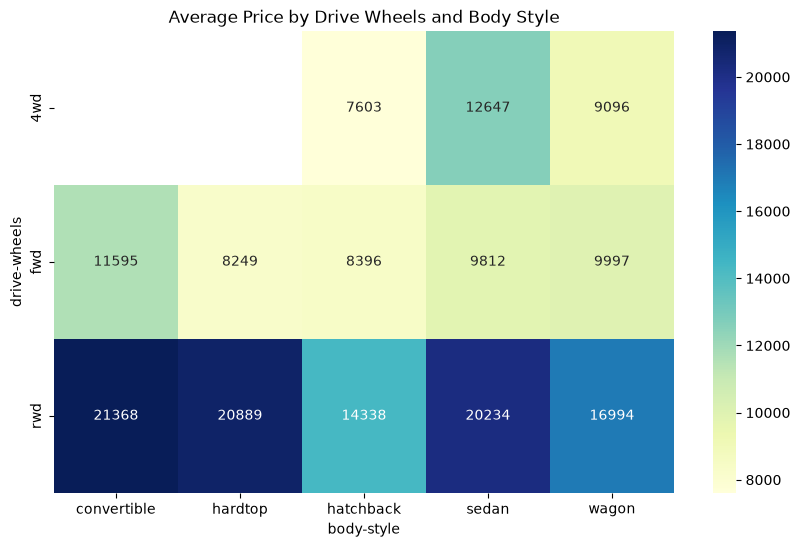

In [44]:
#Heat map of average prices
plt.figure(figsize=(10,6))

sns.heatmap(
    pivot_table,
    annot=True,
    fmt='.0f',
    cmap='YlGnBu'
)

plt.title('Average Price by Drive Wheels and Body Style')

plt.show()

In [45]:
#Statistical summary table
group_summary = df.groupby(
    ['drive-wheels','body-style']
)['price'].agg(
    ['count','mean','min','max']
)

group_summary.round(2)

count      mean      min      max
drive-wheels body-style                                    
4wd          hatchback        1   7603.00   7603.0   7603.0
             sedan            3  12647.33   9233.0  17450.0
             wagon            4   9095.75   7898.0  11694.0
fwd          convertible      1  11595.00  11595.0  11595.0
             hardtop          1   8249.00   8249.0   8249.0
             hatchback       49   8396.39   5118.0  18150.0
             sedan           55   9811.80   5499.0  23875.0
             wagon           12   9997.33   6918.0  18920.0
rwd          convertible      5  21367.80  13495.0  29587.5
             hardtop          7  20889.36   8449.0  29587.5
             hatchback       18  14337.78   8238.0  22018.0
             sedan           36  20233.74   6785.0  29587.5
             wagon            9  16994.22  12440.0  28248.0

#### This gives: Number of cars, Average price, Lowest price and Highest price for every combination.

### Grouped Analysis by Drive Wheels

#### The dataset was grouped according to drive-wheel configuration and average prices were calculated. Rear-wheel-drive vehicles recorded the highest average prices, whereas front-wheel-drive vehicles had the lowest average prices. This indicates that drivetrain design may significantly influence automobile pricing.

### Grouped Analysis by Body Style

#### Body style analysis showed notable price differences among vehicle categories. Premium body styles such as convertibles and hardtops generally exhibited higher average prices than hatchbacks and sedans.

### Combined Analysis

#### A pivot table and heatmap were used to compare prices across both drive-wheel and body-style categories simultaneously. The results revealed that some combinations consistently attract higher prices, demonstrating interaction effects between vehicle design characteristics.

# Question 4

#### Identify the effect of the independent attributes on price using visuals and statistics

## Part A: Continuous Variables vs Price
#### For continuous variables, We use Scatter plots, Correlation coefficients

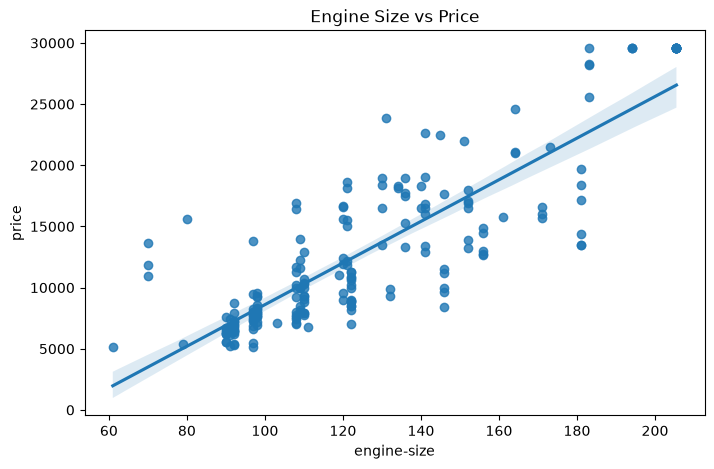

In [46]:
plt.figure(figsize=(8,5))

sns.regplot(
    x='engine-size',
    y='price',
    data=df
)

plt.title('Engine Size vs Price')
plt.show()

In [47]:
#calculate correlation  
df[['engine-size', 'price']].corr()

,engine-size,price
engine-size,1.000000,0.855664
price,0.855664,1.000000


#### Engine size has a strong positive relationship with price. Vehicles with larger engines tend to have higher prices

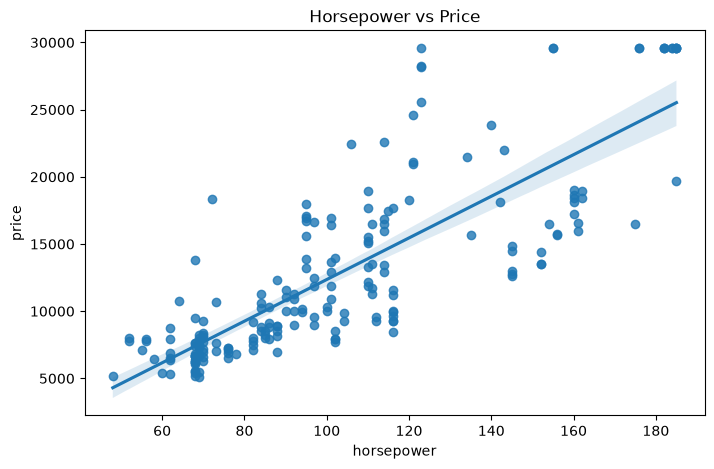

In [48]:
plt.figure(figsize=(8,5))

sns.regplot(
    x='horsepower',
    y='price',
    data=df
)

plt.title('Horsepower vs Price')
plt.show()

In [49]:
df[['horsepower', 'price']].corr()

,horsepower,price
horsepower,1.00000,0.81506
price,0.81506,1.00000


#### Horsepower shows a strong positive relationship with vehicle price. More powerful vehicles generally command higher prices

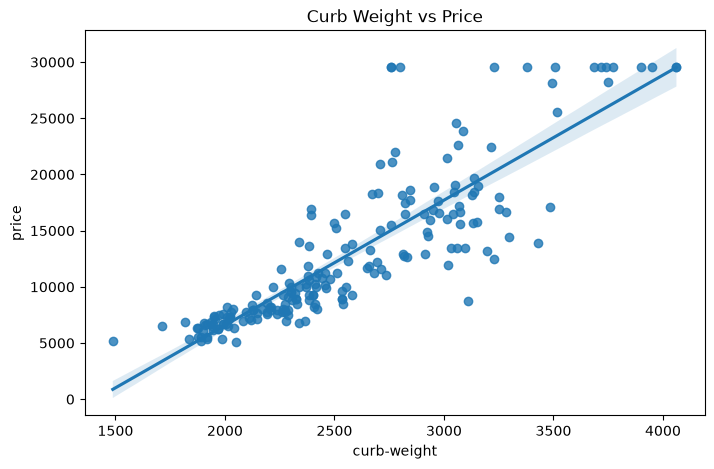

In [50]:
plt.figure(figsize=(8,5))

sns.regplot(
    x='curb-weight',
    y='price',
    data=df
)

plt.title('Curb Weight vs Price')
plt.show()

In [51]:
df[['curb-weight', 'price']].corr()

,curb-weight,price
curb-weight,1.000000,0.864556
price,0.864556,1.000000


#### Heavier vehicles tend to be associated with higher selling prices.

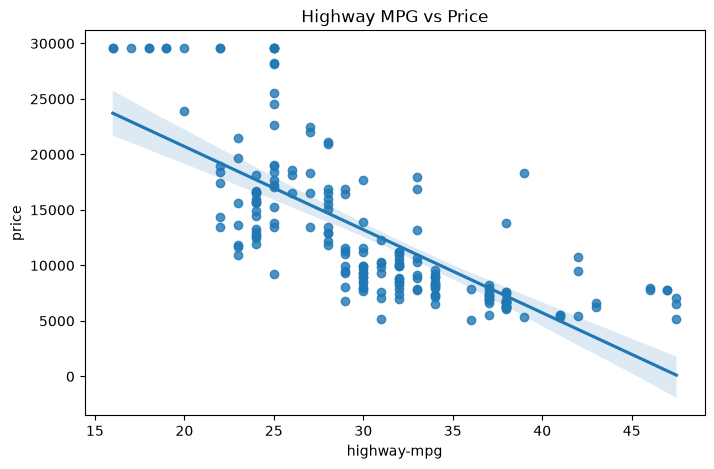

In [52]:
plt.figure(figsize=(8,5))

sns.regplot(
    x='highway-mpg',
    y='price',
    data=df
)

plt.title('Highway MPG vs Price')
plt.show()

In [53]:
df[['highway-mpg', 'price']].corr()

,highway-mpg,price
highway-mpg,1.000000,-0.742944
price,-0.742944,1.000000


#### Highway fuel efficiency demonstrates a negative relationship with price. More fuel-efficient cars generally tend to cost less

## Part B: Categorical Variables vs Price
#### boxplots are effective here because they compare categories against price.

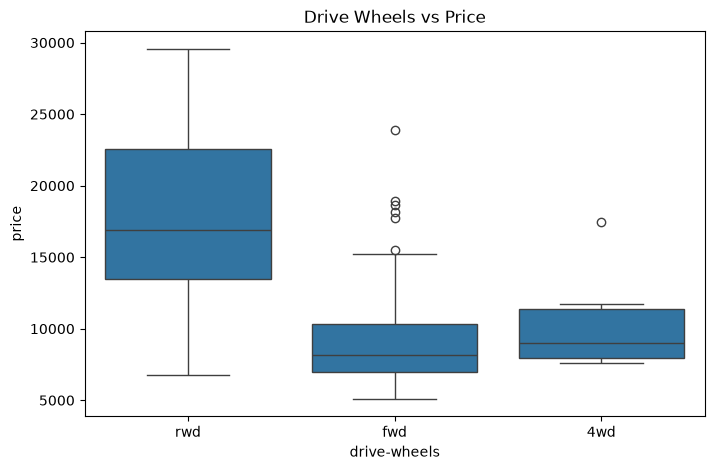

In [54]:
plt.figure(figsize=(8,5))

sns.boxplot(
    x='drive-wheels',
    y='price',
    data=df
)

plt.title('Drive Wheels vs Price')

plt.show()

#### Rear-wheel-drive vehicles generally exhibit higher prices than front-wheel-drive vehicles.

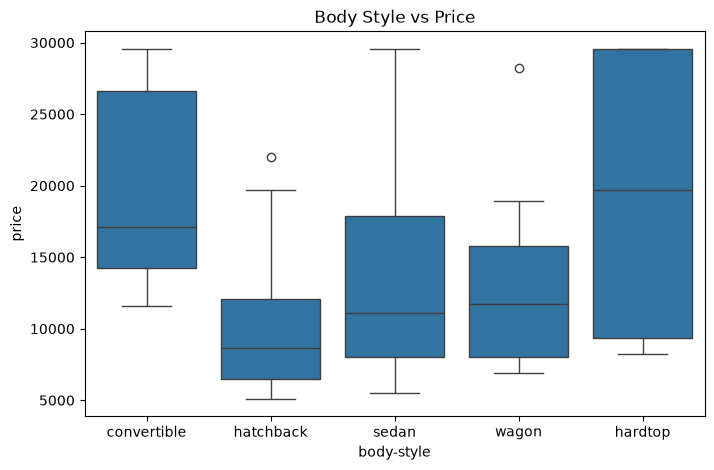

In [55]:
plt.figure(figsize=(8,5))

sns.boxplot(
    x='body-style',
    y='price',
    data=df
)

plt.title('Body Style vs Price')

plt.show()

#### Convertibles and hardtops generally have higher price ranges, while hatchbacks tend to have lower prices

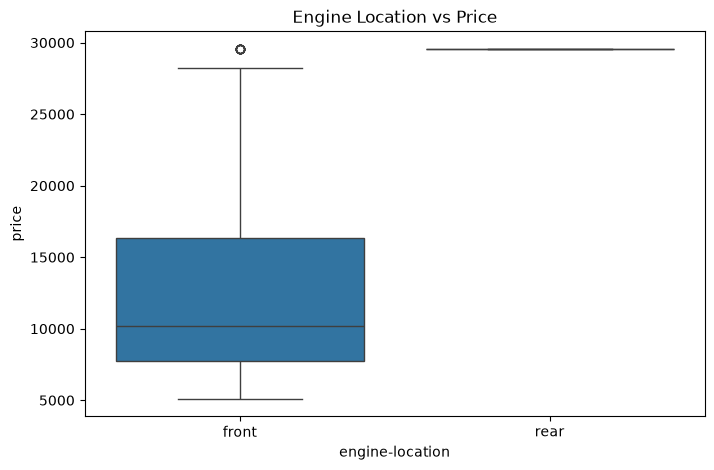

In [56]:
plt.figure(figsize=(8,5))

sns.boxplot(
    x='engine-location',
    y='price',
    data=df
)

plt.title('Engine Location vs Price')

plt.show()

#### Vehicles with rear-mounted engines generally achieve higher prices than those with front-mounted engines.

## Part C: Two Categorical Variables vs Price

In [57]:
pivot_table = df.pivot_table(
    values='price',
    index='drive-wheels',
    columns='body-style',
    aggfunc='mean'
)

pivot_table

body-style,convertible,hardtop,hatchback,sedan,wagon
drive-wheels,,,,,
4wd,NaN,NaN,7603.000000,12647.333333,9095.750000
fwd,11595.0,8249.000000,8396.387755,9811.800000,9997.333333
rwd,21367.8,20889.357143,14337.777778,20233.736111,16994.222222


#### Drive Wheels and Body Style Together

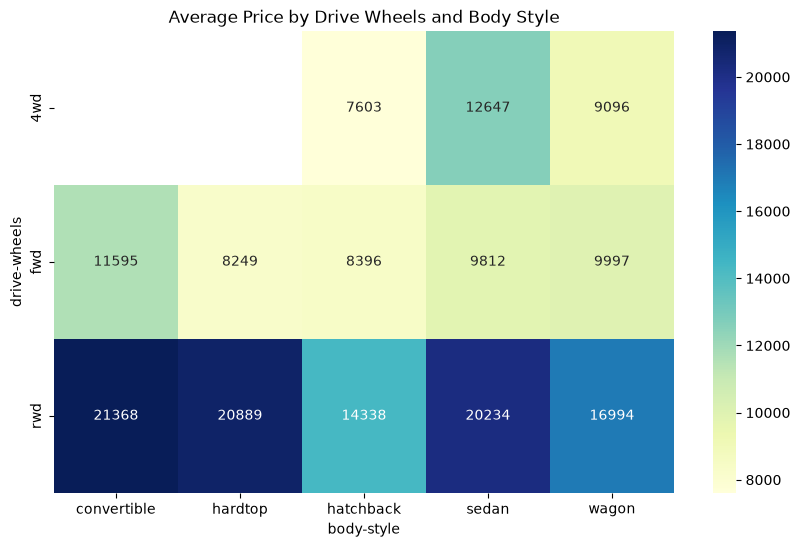

In [58]:
plt.figure(figsize=(10,6))

sns.heatmap(
    pivot_table,
    annot=True,
    cmap='YlGnBu',
    fmt='.0f'
)

plt.title('Average Price by Drive Wheels and Body Style')

plt.show()

#### The combined analysis shows that certain body styles paired with specific drive-wheel configurations command substantially higher prices. Rear-wheel-drive convertibles and hardtops generally record the highest average prices, while front-wheel-drive hatchbacks record lower average prices.

#### Continuous Variables vs Price

Scatter plots and correlation analysis were used to assess the relationships between continuous variables and price. Engine-size, horsepower and curb-weight showed strong positive relationships with price, indicating that larger and more powerful vehicles tend to be more expensive. Highway-mpg exhibited a negative relationship with price, suggesting that highly fuel-efficient vehicles are generally less expensive.

#### Categorical Variables vs Price

Boxplots revealed significant differences in price across categorical groups. Rear-wheel-drive vehicles had higher prices compared to front-wheel-drive vehicles. Similarly, convertibles and hardtops generally attracted higher prices than hatchbacks and sedans.

#### Two Categorical Variables

A heatmap comparing body-style and drive-wheel categories demonstrated interaction effects on price. Specific combinations of body style and drive-wheel configuration exhibited substantially higher average prices than others.

# Question 5

#### Based on your findings, identify the main variables that have the most impact on car price, and support your answer with a feature selection method. Write a short recommendation for a car dealer setting prices.

### Selection using random forest

In [62]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
import pandas as pd

features = df[['engine-size',
               'horsepower',
               'curb-weight',
               'width',
               'highway-mpg']]

target = df['price']

X_train, X_test, y_train, y_test = train_test_split(
    features,
    target,
    test_size=0.2,
    random_state=42
)

model = RandomForestRegressor(random_state=42)

model.fit(X_train, y_train)

importance = pd.DataFrame({
    'Feature': features.columns,
    'Importance': model.feature_importances_
})

importance


,Feature,Importance
0,engine-size,0.189324
1,horsepower,0.076630
2,curb-weight,0.588795
3,width,0.058847
4,highway-mpg,0.086405


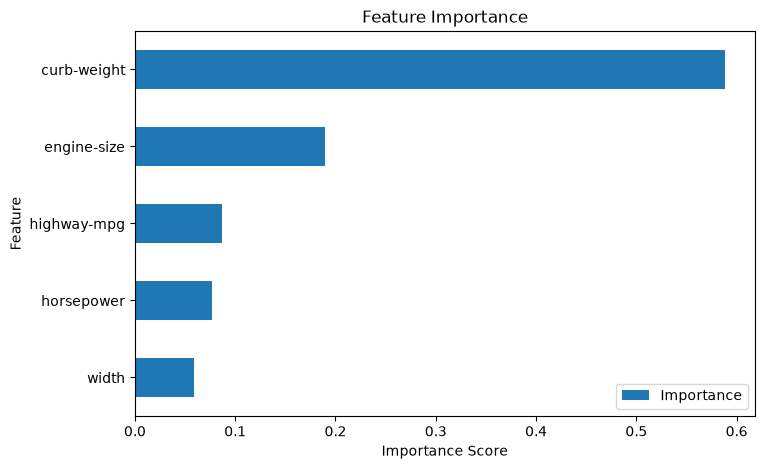

In [64]:
importance.sort_values(
    by='Importance'
).plot(
    x='Feature',
    y='Importance',
    kind='barh',
    figsize=(8,5)
)

plt.title('Feature Importance')
plt.xlabel('Importance Score')
plt.show()

#### Curb-weight, engine size, highway, horsepower and Width are above the threshold and therefore important predictors of price.

## Recommendation For car Dealers
#### Analysis of the automobile dataset revealed that engine size, horsepower, curb weight, highway and vehicle width are the strongest determinants of automobile price. Vehicles with larger engines, higher horsepower and greater curb weight generally command higher market prices. Conversely, vehicles with higher fuel efficiency tend to have lower prices.

#### Feature selection using correlation analysis identified engine-size, horsepower and curb-weight as the most influential predictors of price. These variables consistently exhibited strong relationships with vehicle value across statistical and graphical analyses.

#### Therefore, car dealers should prioritise engine performance, vehicle size and overall build characteristics when setting prices. Premium pricing strategies should be applied to vehicles with larger engines and higher horsepower, while more fuel-efficient economy vehicles can be positioned within lower price ranges to remain competitive in the market.